### Код анализа представленных данных (EDA)

### Описание

Датасет представляет собой совокупность химических дескрипторов - числовых значений, описывающих свойства молекул химических соединений. Для каждого соединения определены целевые переменные IC50 (Half Maximal Inhibitory Concentration), CC50 (Half Maximal Cytotoxic Concentration), SI (Selectivity Index).

В датасете представлено 1001 сэмплов (химических соединений), 213 столбцов. Все данные представленны в числовом формате.

Так как данные уже представленны в виде дескрипторов, они уже машиночитаемы. Значит необходимо произвести EDA в части очистки и подготовки данных только с точки зрения машинного обучения.

1. В датасете было обнаружено 32 дубликата. Они были удалены.

2. Также в небольшом количестве столбцов были обнаружены пропуски. Количество пропусков не более 0,3% от количества значений. В связи с этим было принято решение удалить строки с пропусками.

3. Были проверены целевые переменные на соответсвие положительным значениям. Данные показатели не могут принимать отрицательные или нулевые значения, т.к. IC50 и CC50 — это концентрации вещества, а SI - это отношение IC50 и CC50.

4. Для поиска выбросов и оценки распределения целевых переменных были построены их гистограммы. Графически не наблюдается существенное количество выбросов. Также заметна скошенность распределения. В связи с этим целевые переменные для регрессии будут подвергнуты логарифмированию для приведения их к нормальному распределению для улучшения предсказания моделей.

5. Также была проведена оценка датасета на корреляцию признаков. Опытным путем выяснилось, что удаление признаков с корреляцией > 0.999 положительно сказывается на предсказаниях. Удаление более коррелированных признаков приводило к потере данных и снижении точности предсказаний.

6. Далее были обработаны выбросы. С помощью метода межквартильного размаха были определены границы выбросов. Опытным путем определено, что удаление данных по нижней границе приводит к ухудшению предсказаний. Также опытным путем определена верхняя граница 0,97. Удаление выбросов после этой границы приводило к улучшению предсказаний.

7. Далее были созданы целевые переменные для задач классификации, в соответствии с заданием.

8. Обработанный датасет сохранен для использования в ноутбуках с построением моделей регрессии и классификации.

Также в следующих ноутбуках будет произведено масштабирование данных, разделение их на целевые переменные и признаки, логарифмирование целевых переменных для регрессии, а также разделение данных на тренировочную и тестовую выборки.



In [1]:
# Импортируем необходимые библиотеки
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Загружаем датасет, сразу удаляем колонку индексов
df = pd.read_excel(
    r'/content/Данные_для_курсовои_Классическое_МО.xlsx', index_col=0
)

In [3]:
# Обзор датасета
df.head(2)

,"IC50, mM","CC50, mM",SI,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,...,fr_sulfide,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea
0,6.239374,175.482382,28.125,5.094096,5.094096,0.387225,0.387225,0.417362,42.928571,384.652,...,0,0,0,0,0,0,0,0,3,0
1,0.771831,5.402819,7.000,3.961417,3.961417,0.533868,0.533868,0.462473,45.214286,388.684,...,0,0,0,0,0,0,0,0,3,0


In [4]:
df.info(verbose=True)

<class 'pandas.core.frame.DataFrame'>
Index: 1001 entries, 0 to 1000
Data columns (total 213 columns):
 #    Column                    Dtype  
---   ------                    -----  
 0    IC50, mM                  float64
 1    CC50, mM                  float64
 2    SI                        float64
 3    MaxAbsEStateIndex         float64
 4    MaxEStateIndex            float64
 5    MinAbsEStateIndex         float64
 6    MinEStateIndex            float64
 7    qed                       float64
 8    SPS                       float64
 9    MolWt                     float64
 10   HeavyAtomMolWt            float64
 11   ExactMolWt                float64
 12   NumValenceElectrons       int64  
 13   NumRadicalElectrons       int64  
 14   MaxPartialCharge          float64
 15   MinPartialCharge          float64
 16   MaxAbsPartialCharge       float64
 17   MinAbsPartialCharge       float64
 18   FpDensityMorgan1          float64
 19   FpDensityMorgan2          float64
 20   FpDensityMo

In [5]:
# Исследуем датасет на дубликаты и удаляем их
print(df.duplicated().sum())
df = df.drop_duplicates()

32


In [6]:
# Исследуем датасет на пропуски и удаляем их
missed_values = pd.DataFrame({
    'Кол-во пропусков': df.isnull().sum(),
    'Процент %': (df.isnull().sum() / len(df)) * 100
})

# Выводим только те, где пропусков > 0, и сортируем по убыванию
print(missed_values[missed_values['Кол-во пропусков'] > 0].sort_values(by='Процент %', ascending=False))

df = df.dropna()

                     Кол-во пропусков  Процент %
MaxPartialCharge                    3   0.309598
MinPartialCharge                    3   0.309598
MaxAbsPartialCharge                 3   0.309598
MinAbsPartialCharge                 3   0.309598
BCUT2D_MWHI                         3   0.309598
BCUT2D_MWLOW                        3   0.309598
BCUT2D_CHGHI                        3   0.309598
BCUT2D_CHGLO                        3   0.309598
BCUT2D_LOGPHI                       3   0.309598
BCUT2D_LOGPLOW                      3   0.309598
BCUT2D_MRHI                         3   0.309598
BCUT2D_MRLOW                        3   0.309598


In [7]:
df.shape

(966, 213)

In [8]:
# Проверяем целевые переменные на наличие отрицательных и нулевых значений,
# т.к. таких значений быть не может

df = df[df['IC50, mM'] > 0]
df = df[df['CC50, mM'] > 0]
df = df[df['SI'] > 0]
df.shape

(966, 213)

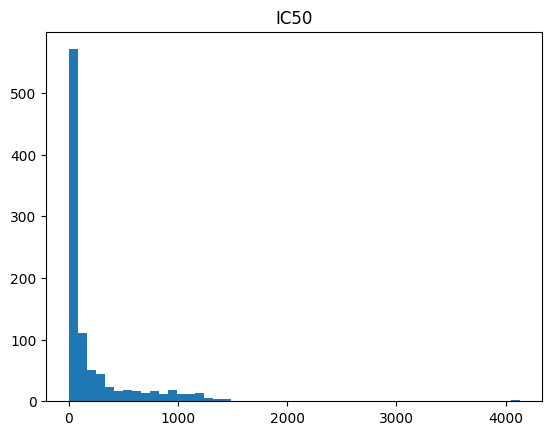

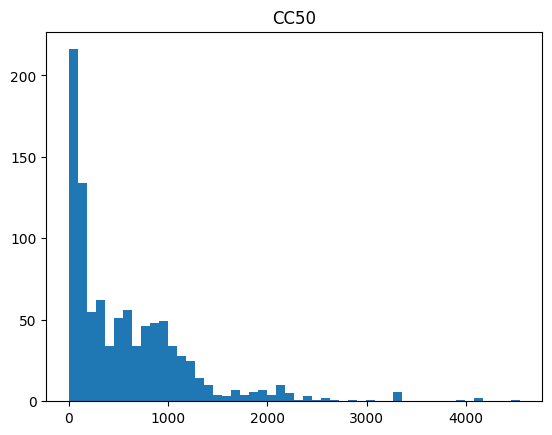

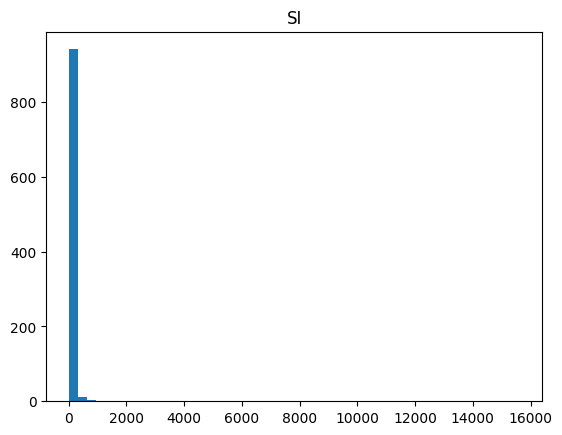

In [9]:
# Проверяем распределение целевых переменных
plt.hist(df['IC50, mM'], bins=50)
plt.title('IC50')
plt.show()

plt.hist(df['CC50, mM'], bins=50)
plt.title('CC50')
plt.show()

plt.hist(df['SI'], bins=50)
plt.title('SI')
plt.show()

In [10]:
# Статистическая информация
df.describe().T

,count,mean,std,min,25%,50%,75%,max
"IC50, mM",966.0,218.977503,395.411527,0.003517,12.491340,45.222783,225.226967,4128.529377
"CC50, mM",966.0,583.888333,632.692383,0.700808,99.999121,422.158836,886.389271,4538.976189
SI,966.0,74.118298,696.637078,0.011489,1.494403,3.913351,16.332455,15620.600000
MaxAbsEStateIndex,966.0,10.891481,3.288861,2.321942,9.895163,12.196998,13.183109,15.933463
MaxEStateIndex,966.0,10.891481,3.288861,2.321942,9.895163,12.196998,13.183109,15.933463
...,...,...,...,...,...,...,...,...
fr_thiazole,966.0,0.053830,0.225799,0.000000,0.000000,0.000000,0.000000,1.000000
fr_thiocyan,966.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
fr_thiophene,966.0,0.070393,0.255941,0.000000,0.000000,0.000000,0.000000,1.000000
fr_unbrch_alkane,966.0,0.209110,1.233286,0.000000,0.000000,0.000000,0.000000,20.000000


In [11]:
# Удаление коррелированных признаков
corr = df.corr(numeric_only=True).abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))

to_drop_corr = [col for col in upper.columns if any(upper[col] > 0.999)]

df = df.drop(columns=to_drop_corr)

In [12]:
# Удаление выбросов
def remove_outliers_iqr(df, cols, k=3):
    df_clean = df.copy()

    for col in cols:
        Q1 = df_clean[col].quantile(0.4)
        Q3 = df_clean[col].quantile(0.97)
        IQR = Q3 - Q1

        upper = Q3 + k * IQR

        df_clean = df_clean[(df_clean[col] <= upper)]

    return df_clean

cols = ['IC50, mM', 'CC50, mM', 'SI', 'MolWt', 'MolLogP', 'TPSA']

df = remove_outliers_iqr(df, cols)

In [13]:
df.shape

(955, 207)

In [14]:
# Создание целевых переменных для классификации
median_ic50 = df['IC50, mM'].median()
df['IC50_above_median'] = (df['IC50, mM'] > median_ic50).astype(int)

median_cc50 = df['CC50, mM'].median()
df['CC50_above_median'] = (df['CC50, mM'] > median_cc50).astype(int)

median_si = df['SI'].median()
df['SI_above_median'] = (df['SI'] > median_si).astype(int)

df['SI_above_8'] = (df['SI'] > 8).astype(int)

In [15]:
df.to_pickle('my_dataset.pkl')